# Analyzing frequencies of chess moves

## Question
Can we see the frequency of chess moves in a dataset of chess games? Are there any patterns or trends in the moves that players make?


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## 1. Load and clean the data
Our data set contains a column called `moves`, which is a string of all the moves made in a game, separated by spaces. We will split this string into a list of individual moves for each game.

In [2]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)

moves = data['moves'].str.split(' ')
print(moves.head())

id
TZJHLljE    [d4, d5, c4, c6, cxd5, e6, dxe6, fxe6, Nf3, Bb...
l1NXvwaE    [d4, Nc6, e4, e5, f4, f6, dxe5, fxe5, fxe5, Nx...
mIICvQHh    [e4, e5, d3, d6, Be3, c6, Be2, b5, Nd2, a5, a4...
kWKvrqYL    [d4, d5, Nf3, Bf5, Nc3, Nf6, Bf4, Ng4, e3, Nc6...
9tXo1AUZ    [e4, e5, Nf3, d6, d4, Nc6, d5, Nb4, a3, Na6, N...
Name: moves, dtype: object


## 2. Preprocessing the data
Before we can create a frequency table of the moves, we need to preprocess the moves.

Currently, the moves are in algebraic notation, which is a standard way of recording chess moves. However, we will need to convert them into a more uniform 'target square' format, which consists of the index of the rank and the file of the square that the piece is moving to. For example, the move `e4` would be converted to `[5, 4]` (1-indexed), since it is moving to the 4th rank and 5th file.

In [3]:
def notation_to_index(move, index) -> tuple[int, int]:
    # Check if the move is a castling move
    if move == 'O-O':
        if index % 2 == 0:  # White's turn
            return (7, 1)  # g1
        else:  # Black's turn
            return (7, 8)  # g8
    elif move == 'O-O-O':
        if index % 2 == 0:  # White's turn
            return (3, 1)  # c1
        else:  # Black's turn
            return (3, 8)  # c8
    
    # Check if the move is a promotion move
    if '=' in move:
        move = move.split('=')[0]  # Remove the promotion part

    # Remove any check or checkmate symbols
    move = move.strip('#+')

    # Extract the target square (last two characters)
    target_square = move[-2:]

    # Convert the target square to coordinates
    file = ord(target_square[0].lower()) - ord('a') + 1
    rank = int(target_square[1])

    return (file, rank)

# Parse each move into its target square (E4 -> [5, 4])
moves_parsed = moves.apply(
    lambda game: [
        notation_to_index(move.rstrip("+#"), i) for i, move in enumerate(game)
    ]
)
moves_parsed.head()

id
TZJHLljE    [(4, 4), (4, 5), (3, 4), (3, 6), (4, 5), (5, 6...
l1NXvwaE    [(4, 4), (3, 6), (5, 4), (5, 5), (6, 4), (6, 6...
mIICvQHh    [(5, 4), (5, 5), (4, 3), (4, 6), (5, 3), (3, 6...
kWKvrqYL    [(4, 4), (4, 5), (6, 3), (6, 5), (3, 3), (6, 6...
9tXo1AUZ    [(5, 4), (5, 5), (6, 3), (4, 6), (4, 4), (3, 6...
Name: moves, dtype: object

## 3. Counting the frequency of each move
We will create a new DataFrame that contains the frequency of each move across all games. We can use the preprocessed moves to count how many times each move was made in the dataset. This will allow us to see which moves are the most common and which are the least common.

In [4]:
def count_frequencies(moves_parsed):
    heatmap = np.zeros((8, 8))
    for game in moves_parsed:
        for move in game:
            if move is not None:
                file, rank = move
                heatmap[rank - 1, file - 1] += 1
    return heatmap

## 4. Visualizing the frequency of moves
Finally, we will create a heatmap to visualize the frequency of each move. The heatmap will show the frequency of moves on the chessboard, with the x-axis representing the files (a-h) and the y-axis representing the ranks (1-8). The color intensity will indicate how frequently each square was targeted by a move.

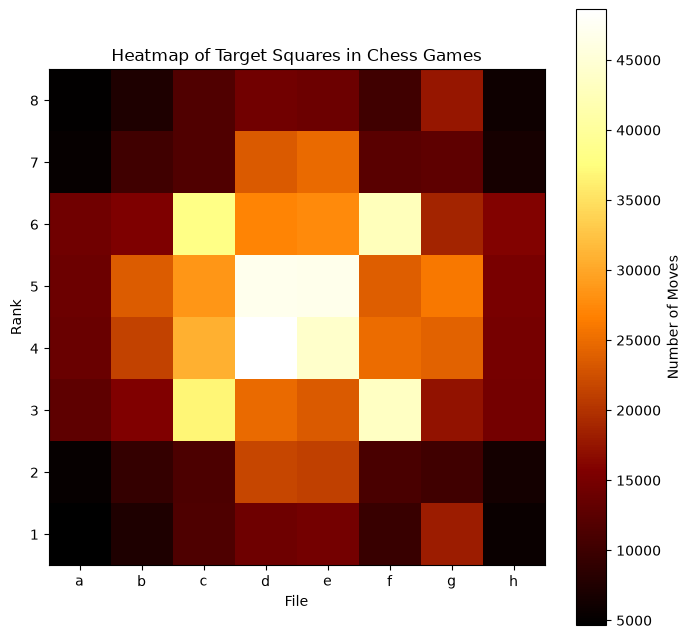

In [5]:
# Create a heatmap of the target squares
heatmap = count_frequencies(moves_parsed)

# Plot the heatmap 
plt.figure(figsize=(8, 8))
plt.imshow(heatmap[::-1], cmap='afmhot', interpolation='none')
plt.colorbar(label='Number of Moves')
plt.xticks(ticks=np.arange(8), labels=['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'])
plt.yticks(ticks=np.arange(8), labels=np.arange(1, 9, )[::-1])
plt.title('Heatmap of Target Squares in Chess Games')
plt.xlabel('File')
plt.ylabel('Rank')
plt.savefig('../Resources/heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Insights
We can identify patterns and trends from the heatmap. For example, we can see that central squares like e4 and d4 are more frequently targeted, which aligns with common opening strategies in chess. Additionally, we can observe that certain squares are rarely targeted, indicating less common moves or strategies. 

We can also see squares like `g1` and `g8` which are the targeted squares when castling the king king-side. They are brighter than the squares `c1` and `c8` which are the targeted squares when castling the queen-side. This indicates that players prefer to castle king-side more often than queen-side.

Another observation is squares `c3`, `f3`, `c6`, and `f6` which are the targeted squares when moving the knight to the center of the board. They are brighter than the squares `b3`, `g3`, `b6`, and `g6` which are the targeted squares when moving the knight to the edge of the board. This indicates that players prefer to move their knights to the center of the board more often than to the edge of the board. 

What happens if we limit the heatmap to the last `n` plies (half-moves)? Will the heatmap look different if we look at only end games?

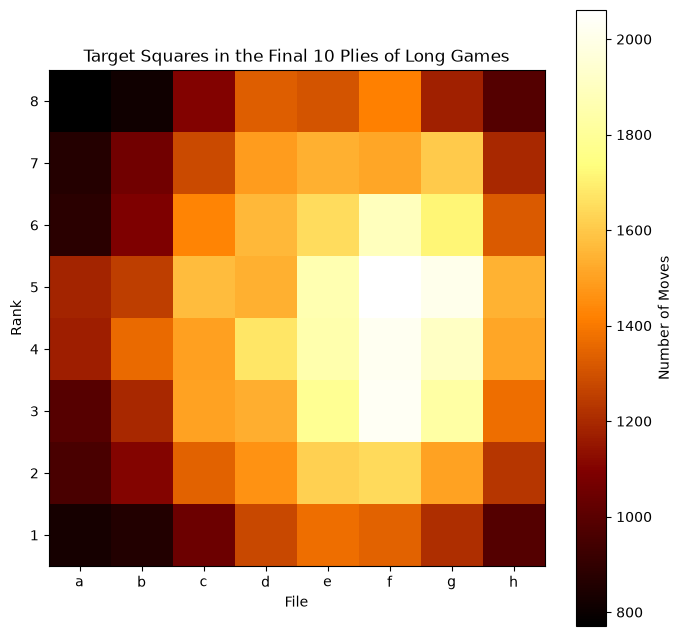

In [6]:
last_plies_limit = 10
games_with_enough_moves = moves_parsed[moves_parsed.apply(len) >= 60]

# Limit the moves to the last n moves of each game
moves_parsed_limit = games_with_enough_moves.apply(lambda game: game[-last_plies_limit:])

heatmap = count_frequencies(moves_parsed_limit)

# Plot the heatmap 
plt.figure(figsize=(8, 8))
plt.imshow(heatmap[::-1], cmap='afmhot', interpolation='none')
plt.colorbar(label='Number of Moves')
plt.xticks(ticks=np.arange(8), labels=['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'])
plt.yticks(ticks=np.arange(8), labels=np.arange(1, 9, )[::-1])
plt.title(f'Target Squares in the Final {last_plies_limit} Plies of Long Games')
plt.xlabel('File')
plt.ylabel('Rank')
plt.show()

## Conclusion

The full-game heatmap shows that central squares, especially `d4` and `e4`, are targeted most often. This reflects common opening principles, where players compete for control of the centre. The map also shows that king-side castling is more common than queen-side castling, and that knights are generally developed towards central squares rather than the edges of the board.

When only the final `n` plies are considered, the opening patterns become less prominent. Moves are distributed more broadly across the board because the position is more dynamic and pieces, particularly kings, become more active during the endgame. The final-move heatmap therefore differs from the full-game heatmap and better reflects endgame movement and tactical activity.

However, this analysis uses only games with at least 60 plies and counts raw moves rather than normalising by the number of games. Therefore, the final heatmap should be interpreted as a description of move frequency in this selected group, not as a definitive representation of all chess endgames.